## Setup

Turns on `autoreload` so edits to the `wyscout` package are picked up without restarting the kernel. No output.

In [10]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Imports and environment

Loads the Wyscout credentials from `.env`, points `MONGO_HOST` at the local Mongo cache that every API call is stored in, and imports the shared helpers. No output.

In [11]:
from typing import List, Dict, Any
import sys
from dotenv import load_dotenv
load_dotenv()
import os
# os.environ['MONGO_HOST'] = "192.168.1.207"
os.environ['MONGO_HOST'] = "localhost"
import pandas as pd
sys.path.append('..')
from wyscout.match import get_team_matches, get_match_details
from wyscout.stats import get_touches_for_player
from wyscout.competitions import get_competitions, get_competition_seasons
import seaborn as sns
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np

## IDs and the season under analysis

Wyscout IDs for the competition, the teams and the players referenced below, plus one constant per National League season.

`SEASON` is what the rest of the notebook runs against - currently `SEASON_2026`, the 2026/27 season. Point it at another constant to re-run everything for a different year.

In [12]:
NATIONAL_LEAGUE = 351

SOUTHEND = 1687
NOTTS_C = 1677
WREXHAM = 10530
BARNET = 1701
WEALDSTONE = 1833
BOREHAM_WOOD = 1917
EASTLEIGH = 1772

SEASON_2021 = 187596
SEASON_2022 = 188172
SEASON_2023 = 189051
SEASON_2024 = 190045
SEASON_2025 = 191757
SEASON_2026 = 192798

J_BRIDGE = 289901
S_HOBSON = 489434
C_POWELL = 444130
M_DAKERS = 601997
K_LOPATA = 592169
H_CARDWELL = 330285
G_SCOTT_MORRISS = 486095

SEASON = SEASON_2026

## Fixture list for the season

Fetches Southend's matches for `SEASON` and prints the id, date and label of each, so a specific `matchId` can be picked out for the single-match cells further down.

Also sets the `match_id` and `team_id` defaults used later. Output: a plain text list.

In [13]:
matches = get_team_matches(SOUTHEND, SEASON)
for m in matches["matches"]:
    print(m["matchId"], m["date"], m["label"])

match_id = matches["matches"][0]["matchId"]
team_id = SOUTHEND 

5864960 2026-09-19 16:00:00 Gateshead - Southend United, 1-6
5864944 2026-09-15 20:45:00 Southend United - Tamworth, 3-1
5864938 2026-09-12 18:30:00 Carlisle United - Southend United, 2-2
5864917 2026-09-05 13:30:00 Southend United - Yeovil Town, 3-2
5864912 2026-08-31 16:00:00 Woking - Southend United, 1-1
5864900 2026-08-28 20:45:00 Southend United - Kidderminster Harriers, 1-3
5864886 2026-08-22 13:30:00 Solihull Moors - Southend United, 1-3
5864873 2026-08-15 16:00:00 Southend United - Scunthorpe United, 1-0
5864856 2026-08-08 16:00:00 Altrincham - Southend United, 1-3


## Attempts split by possession share

Splits the season's matches into two buckets - under and over 55% possession - using the advanced stats endpoint, then maps the attempts in each.

**Visualisation:** two vertical half-pitches side by side, one bucket each. Marker position is where the shot was taken, marker size is xG, a red ring means it went in, and the darker shade means on target. Tiles underneath give matches, attempts, goals and xG, both totals and per game.

Note the header text is hardcoded to 2025/26 - update it when `SEASON` changes.

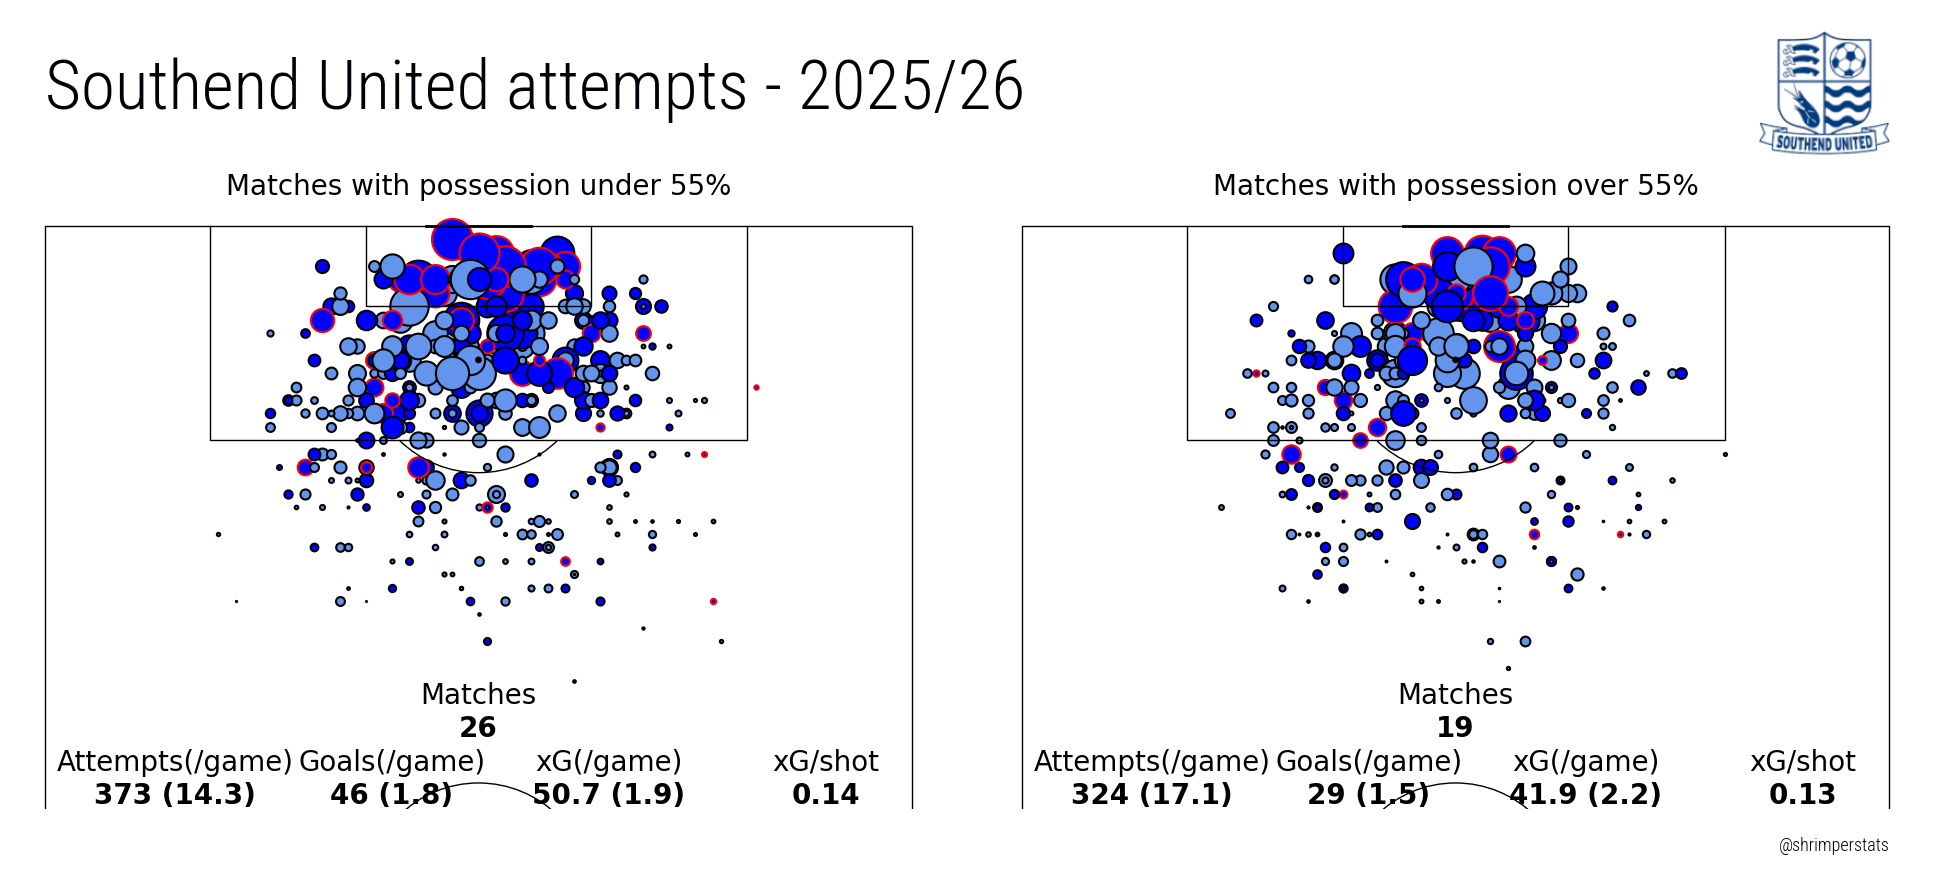

In [6]:
from wyscout.match import get_match_advanced_stats
from wyscout.viz.match import plot_attempts

matches = get_team_matches(team_id=team_id, season_id=SEASON)

matches_1 = []
matches_2 = []

pct = 55

def get_possession(match_id, team_id):
    stats = get_match_advanced_stats(match_id)
    goals = stats["general"][str(team_id)]["goals"]
    possession = stats["possession"][str(team_id)]["possessionPercent"]
    return goals, possession

for m in matches["matches"]:
    try:
        goals, percent = get_possession(m["matchId"], team_id)
        if percent >= pct:
            matches_1.append(m)
        else:
            matches_2.append(m)
    except:
        pass

plot_attempts(
    [matches_2, matches_1],
    # [matches_under_55[0:1], matches_over_55[0:0]],
    team_id,
    fig_height=10,
    shot_colors=("blue", "cornflowerblue"),
    header_text=f"Southend United attempts - 2025/26",
    subtitle_text=[
        f"Matches with possession under {pct}%",
        f"Matches with possession over {pct}%"
    ],
    include_pens=False,
)

## Action map for every match of the season

**Visualisation:** a grid of half-pitches, one per played match, five to a row. Each shows a heat map of Southend's touches in that match with the attempts plotted on top, titled with the opposition, date and result. `reversed=True` puts the oldest match first.

In [ ]:
from wyscout.viz.player import plot_team_season_heat_maps
team_id = SOUTHEND
season = SEASON
plot_team_season_heat_maps(
    team_id,
    season,
    cols=5,
    fig_height=50,
    cmap="Blues",
    shot_colors=("blue", "cornflowerblue"),
    reversed=True,
)

## One player's match-by-match heat maps

Same grid for a single player - `player_id`, currently George Scott-Morriss.

**Visualisation:** one half-pitch per match showing where he touched the ball, with his attempts marked, sized by xG. His photo and name go in the header.

In [ ]:
from wyscout.viz.player import plot_player_season_heat_maps


player_id = G_SCOTT_MORRISS
team_id = SOUTHEND
season = SEASON

plot_player_season_heat_maps(player_id, team_id, season, cols=5, fig_height=40)


## Who passes to whom

Counts every completed pass between team mates across the season's matches, treating a pass to nobody as *Incomplete* and one to an opponent as *Opposition*.

**Visualisation:** a passer-by-recipient matrix as a blue heat map with the count written in each square. It is a very wide figure, so expect to scroll sideways. Returns the raw counts and the player list.

In [ ]:
from wyscout.viz.viz import pass_heat_map_for_matches
passes, players = pass_heat_map_for_matches(team_id, [int(m["matchId"]) for m in matches["matches"]])

## Attacking contribution by player

**Visualisation:** four stacked bar charts, one row per metric, sharing a player axis and badged with the club crest:

1. post-shot xG minus xG - finishing above or below the quality of chance
2. xG against goals scored
3. attempts against attempts on target
4. average xG per attempt - chance quality

Colours are passed in, so the same chart can be redrawn in another club's palette.

In [ ]:
from wyscout.viz.xg import plot_attacking_stats
colors = ["royalblue", "yellow"]
edgecolors = ["royalblue", "yellow"]

plot_attacking_stats(SOUTHEND, SEASON, colors=colors, edgecolors=edgecolors)


### The same breakdown for Notts County (2022/23)

A comparison team, in black and white.

In [ ]:
colors = ["black", "white"]
edgecolors = ["black", "black"]

plot_attacking_stats(NOTTS_C, SEASON_2022, colors=colors, edgecolors=edgecolors)


### The same breakdown for Wrexham (2022/23)

A comparison team, in red and white.

In [ ]:
colors = ["red", "white"]
edgecolors = ["red", "red"]

plot_attacking_stats(WREXHAM, SEASON_2022, colors=colors, edgecolors=edgecolors)


### The same breakdown for Boreham Wood (2022/23)

A comparison team, in black and white.

In [ ]:
colors = ["black", "white"]
edgecolors = ["black", "black"]

plot_attacking_stats(BOREHAM_WOOD, SEASON_2022, colors=colors, edgecolors=edgecolors)

## Put the fixtures in chronological order

Reverses the match list into oldest-first, which the game-by-game charts below rely on for their left-to-right time axis. No output.

In [ ]:
all_matches = matches["matches"]
all_matches.reverse()

## Build the game-by-game xG table

Walks every played match, counts attempts, goals and xG, and works out xG per shot for the match, for the season to date, and across the last five games. Each match is also tagged 0/1/2 for loss/draw/win.

Produces the `df` DataFrame that the next few charts draw from. No visualisation of its own.

In [ ]:
from wyscout.match import get_match_details_and_events

def get_shot_stats(events: List[Dict[str, Any]]) -> Dict[str, Any]:
    shots = [e for e in events if e["type"]["primary"] == "shot"]
    goals_agg = sum([s["shot"]["isGoal"] for s in shots])
    xg_agg = sum([s["shot"]["xg"] for s in shots])
    return {
        "shots": len(shots),
        "goals": goals_agg,
        "xG": xg_agg
    }

xg_stats = {
    "shots": [],
    "goals": [],
    "xG": [],
    "xg_per_shot": [],
    "rolling_xg_per_shot": [],
    "rolling_5_xg_per_shot": [],
    "result": [],
    "label": []
}

shots_goals = {
    "count": [],
    "type": [],
    "label": []
}
for m in all_matches:
    if (m["status"] != "Played"):
        continue
    try:
        match, match_details, squad, team_details = get_match_details_and_events(
            team_id, m["matchId"], False)
    except ValueError:
        continue

    stats = get_shot_stats(match["events"])

    # 0 = loss, 1 = won, 2 = win
    result = 2 if match_details["winner"] == team_id else 0 if match_details["winner"] != 0 else 1

    xg_stats["result"].append(result)
    xg_stats["shots"].append(stats["shots"])
    xg_stats["goals"].append(stats["goals"])
    xg_stats["xG"].append(stats["xG"])
    xg_stats["xg_per_shot"].append(stats["xG"] / stats["shots"])
    xg_stats["rolling_xg_per_shot"].append(sum(xg_stats["xG"]) / sum(xg_stats["shots"]))
    xg_stats["rolling_5_xg_per_shot"].append(sum(xg_stats["xG"][-5:]) / sum(xg_stats["shots"][-5:]))
    xg_stats["label"].append(m["label"])

    shots_goals["count"].append(stats["shots"])
    shots_goals["type"].append("shots")
    shots_goals["label"].append(m["label"])

    shots_goals["count"].append(stats["goals"])
    shots_goals["type"].append("goals")
    shots_goals["label"].append(m["label"])

df = pd.DataFrame(xg_stats)
df_shots_goals = pd.DataFrame(shots_goals)


## Chance quality and volume, game by game

**Visualisation:** a dual-axis chart across the season. On the left axis, blue bars are xG per shot for each match, the pale line is the season-long rolling average and the gold line the rolling average over the last five games. On the right axis, dark red bars are attempts and bright red bars are goals. The background is shaded red-to-green by result, so form is readable behind the bars.

In [ ]:
sns.set_theme(style="whitegrid")

sns.set(rc={'figure.figsize':(15,9)})

ax1 = sns.lineplot(
    data=df, y="rolling_xg_per_shot", x="label", palette="dark", color="lightsteelblue", linewidth=2
)

ax1.tick_params(axis='x', rotation=90)


sns.lineplot(
    x='label', 
    y='rolling_5_xg_per_shot', 
    data=df, 
    color='gold',
    linewidth=2,
    ax = ax1
)

sns.barplot(
    x='label', 
    y='xg_per_shot', 
    data=df, 
    color='blue', 
    ax = ax1
)

ax1.set(xlabel=None)
ax1.set(ylabel="xG/shot")

ax2 = ax1.twinx()

sns.barplot(
    data=df, x="label", y="shots", color="darkred", alpha=0.5, width=0.3,
    ax=ax2
)


sns.barplot(
    data=df, x="label", y="goals", color="red",
    ax=ax2
)

ax2.set(ylabel="Attempts and Goals count")
ax2.grid(False)

a = Line2D([], [], color='lightsteelblue', label='Rolling xG/shot for season', linewidth=2)
b = Line2D([], [], color='gold', label='Rolling xG/shot for last 5 games', linewidth=2)
c = Line2D([], [], color='blue', label='xG/shot for game')
d = Line2D([], [], color='darkred', alpha=0.3, label='Attempts for game')
e = Line2D([], [], color='red', label='Goals')
plt.legend(handles=[a, b, c, d, e])


ax1.pcolorfast(ax1.get_xlim(), ax1.get_ylim(),
              df["result"].values[np.newaxis],
              cmap='RdYlGn', alpha=0.2)


## Goals against xG and post-shot xG

Prints a per-match line of goals, xG and post-shot xG - penalties included here - and the season totals underneath.

The gap between xG and post-shot xG is finishing: post-shot xG above xG means shots were placed better than the average attempt from those positions. Output: text only.

In [ ]:
from wyscout.match import get_match_details_and_events

def get_shot_stats(events: List[Dict[str, Any]]) -> Dict[str, Any]:
    shots = [e for e in events if e["type"]["primary"] in ["shot", "penalty"]]
    goals_agg = sum([s["shot"]["isGoal"] for s in shots])
    xg_agg = sum([s["shot"]["xg"] for s in shots])
    post_shot_xg_agg = sum([s["shot"]["postShotXg"] or 0 for s in shots])
    return {
        "shots": len(shots),
        "goals": goals_agg,
        "xG": xg_agg,
        "postShotXg": post_shot_xg_agg
    }
   
total_goals = 0
total_xg = 0
total_post_shot_xg = 0

for m in matches["matches"]:
    try:
        match, match_details, squad, team_details = get_match_details_and_events(
            team_id, m["matchId"], False)
    except ValueError:
        continue

    stats = get_shot_stats(match["events"])

    total_goals += stats["goals"]
    total_xg += stats["xG"]
    total_post_shot_xg += stats["postShotXg"]

    print(f"{m['label']}: {stats['goals']} goals, {stats['xG']} xG, {stats['postShotXg']} post-shot xG")

print(f"Goals: {total_goals}")
print(f"xG: {total_xg}")
print(f"Post-shot xG: {total_post_shot_xg}")


## xG against goals, game by game

**Visualisation:** paired bars per match - blue for xG, red for goals - with a five-game rolling xG line over the top and the result shading behind. A cleaner read than the chart above when the question is just whether the goals are keeping up with the chances.

In [ ]:
sns.set_theme(style="whitegrid")
sns.set(rc={'figure.figsize': (15, 6)})

fig, ax1 = plt.subplots()

x = np.arange(len(df))
width = 0.35

bars_xg = ax1.bar(x - width / 2, df["xG"], width=width, color="royalblue", label="xG")
bars_goals = ax1.bar(x + width / 2, df["goals"], width=width, color="red", label="Goals")

rolling_xg = df["xG"].rolling(5, min_periods=1).mean()
ax1.plot(x, rolling_xg, color="lightsteelblue", linewidth=2, label="Rolling 5-game xG")

ax1.set_xticks(x)
ax1.set_xticklabels(df["label"], rotation=90)
ax1.set(ylabel="xG / Goals", xlabel=None)

ax1.pcolorfast(
    ax1.get_xlim(), ax1.get_ylim(),
    df["result"].values[np.newaxis],
    cmap="RdYlGn", alpha=0.15,
)

ax1.legend()
plt.tight_layout()
plt.show()


## Single match to inspect

Sets the `MATCH_ID` used by the ad-hoc cells below. No output.

In [ ]:
MATCH_ID = 5613727

## Goals that came from corners

Scans every match for corners whose possession sequence ended in a goal, for Southend and for the opposition, and prints the match and the time on the clock. Output: text only.

In [ ]:
from wyscout.match import get_match_details_and_events


for m in matches["matches"]:
    try:
        match, match_details, squad, team_details = get_match_details_and_events(
            team_id, m["matchId"], True)
    except ValueError:
        continue

    southend_events = [e for e in match["events"] if e["team"]["id"] == SOUTHEND]
    southend_corners = [e for e in southend_events if e["type"]["primary"] == "corner" ]
    for c in southend_corners:
        if c["possession"]["attack"] is not None and c["possession"]["attack"]["withGoal"] == True:
            print(f"Southend goal - {m['label']}: {c['minute']} {c['second']}")

    oppo_events = [e for e in match["events"] if e["opponentTeam"]["id"] == SOUTHEND]
    oppo_corners = [e for e in oppo_events if e["type"]["primary"] == "corner" ]
    for c in oppo_corners:
        if c["possession"]["attack"] is not None and c["possession"]["attack"]["withGoal"] == True:
            print(f"Oppo goal - {m['label']}: {c['minute']} {c['second']}")


## Scratch: pull one opponent's events

Filters the last loaded match down to York's events for the ad-hoc digging in the next few cells.

In [ ]:
york_id = 1699
york_events = [e for e in match["events"] if e["team"]["id"] == york_id]

## Scratch: count their corners

In [ ]:
corners = [e for e in york_events if e["type"]["primary"] == "corner" ]
len(corners)

# [e for e in york_events if e["type"]["primary"] == "corner" and e["possession"]["attack"]["withGoal"] == True ]


## Scratch: look at the corner events

In [ ]:
[c for c in corners]

## Scratch: find their goals in the event list

In [ ]:
[i for i,e in enumerate(york_events) if e["type"]["primary"] == "shot" and e["shot"]["isGoal"] == True]

## Scratch: what happened immediately before the goal

Steps back one event from the first goal - usually enough to see whether it came from a corner, a cross or open play.

In [ ]:
goal_indices = [i for i,e in enumerate(york_events) if e["type"]["primary"] == "shot" and e["shot"]["isGoal"] == True]
if goal_indices:
    york_events[goal_indices[0] - 1]

## League table at a given date

Rebuilds the National League table as it stood on a chosen date from the results up to that point. Output: the table printed as CSV, ready to paste into a spreadsheet.

Note this cell is pinned to `SEASON_2024` and 25 December 2024 rather than `SEASON`.

In [ ]:
from wyscout.league_table import league_table_at_date


# table = league_table_at_date(SEASON_2024, "2025-06-01", "2024-12-25")
table = league_table_at_date(SEASON_2024, NATIONAL_LEAGUE, "2024-12-25")

# print csv headers
print("Pos,Team,P,W,D,L,F,A,GD,Pts")
for i, t in enumerate(table):
    # print csv
    print(f"{t['position']},{t['team_name']},{t['played']},{t['won']},{t['drawn']},{t['lost']},{t['goals_for']},{t['goals_against']},{t['goal_difference']},{t['points']}")


## Cumulative xG against cumulative goals

**Visualisation:** a dark two-panel chart. The top panel runs cumulative xG and cumulative goals across the season, shading the gap blue where xG leads (underperforming) and red where goals lead (overperforming), with W/D/L markers along the bottom. The lower panel plots that gap on its own, with the final figure called out. The x axis is shortened fixture labels - `vs` for home, `@` for away.

Note the chart title is hardcoded to 2024/25 - update it when `SEASON` changes.

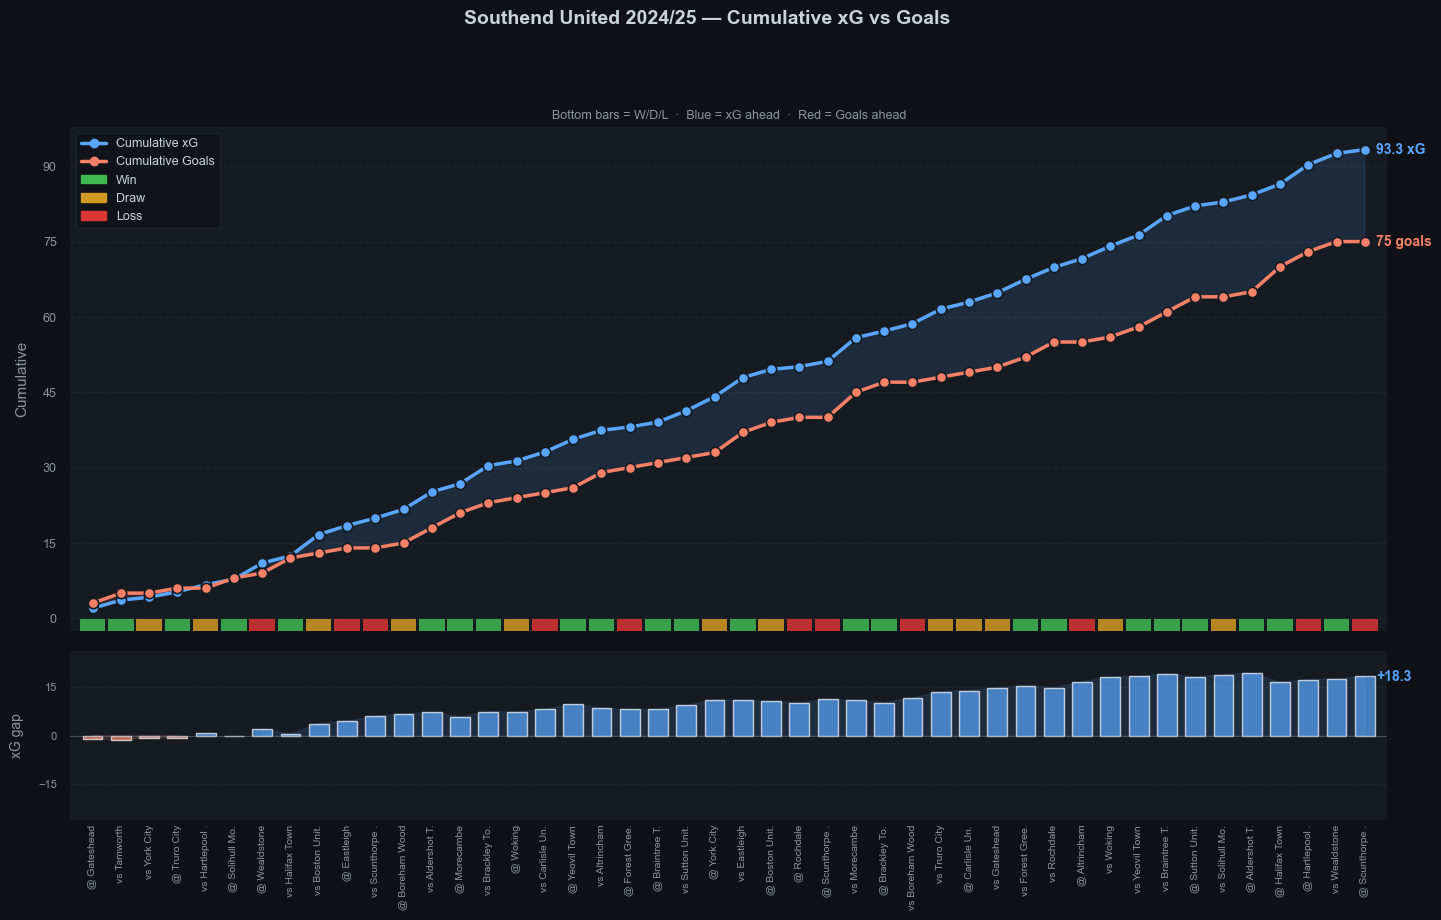

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import numpy as np

df_cum = df.copy()
df_cum["cum_xG"] = df["xG"].cumsum()
df_cum["cum_goals"] = df["goals"].cumsum()
df_cum["gap"] = df_cum["cum_xG"] - df_cum["cum_goals"]
df_cum["game"] = range(1, len(df) + 1)

def shorten_label(label):
    parts = label.split(",")[0]
    teams = parts.split(" - ")
    if "Southend" in teams[0]:
        opponent, home = teams[1].strip(), True
    else:
        opponent, home = teams[0].strip(), False
    short = opponent[:11] + "." if len(opponent) > 12 else opponent
    return ("vs " if home else "@ ") + short

df_cum["short_label"] = df["label"].apply(shorten_label)

BG      = "#0f1117"
PANEL   = "#161b22"
XG_COL  = "#58a6ff"
GOL_COL = "#f78166"
TEXT    = "#c9d1d9"
MUTED   = "#8b949e"
GRID    = "#21262d"
W_COL   = "#3fb950"
D_COL   = "#d29922"
L_COL   = "#da3633"

x    = df_cum["game"].values
xg   = df_cum["cum_xG"].values
gols = df_cum["cum_goals"].values
gap  = df_cum["gap"].values

fig, (ax, ax2) = plt.subplots(
    2, 1, figsize=(17, 9),
    sharex=True,
    gridspec_kw={"height_ratios": [3, 1], "hspace": 0.06},
)
fig.patch.set_facecolor(BG)

for a in (ax, ax2):
    a.set_facecolor(PANEL)
    for spine in a.spines.values():
        spine.set_visible(False)

# ── top: cumulative xG vs goals ──────────────────────────────────────────────
ax.fill_between(x, xg, gols, where=(xg >= gols), color=XG_COL,  alpha=0.12, zorder=2)
ax.fill_between(x, xg, gols, where=(xg <  gols), color=GOL_COL, alpha=0.12, zorder=2)

ax.plot(x, xg,   color=XG_COL,  linewidth=2.5, zorder=5, solid_capstyle="round")
ax.plot(x, gols, color=GOL_COL, linewidth=2.5, zorder=5, solid_capstyle="round")

ax.scatter(x, xg,   color=XG_COL,  s=55, zorder=6, edgecolors=PANEL, linewidth=1.2)
ax.scatter(x, gols, color=GOL_COL, s=55, zorder=6, edgecolors=PANEL, linewidth=1.2)

result_map = {2: W_COL, 1: D_COL, 0: L_COL}
for game, result in zip(x, df_cum["result"]):
    ax.axvspan(game - 0.45, game + 0.45, ymin=0, ymax=0.025,
               color=result_map[result], alpha=0.85, zorder=4, lw=0)

ax.tick_params(axis="y", colors=MUTED, labelsize=9)
ax.tick_params(axis="x", length=0, labelbottom=False)
ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True))
ax.yaxis.grid(True, color=GRID, linewidth=0.8, linestyle="--", zorder=0)
ax.xaxis.grid(False)
ax.set_axisbelow(True)
ax.set_ylabel("Cumulative", fontsize=11, color=MUTED, labelpad=10)

pad = 0.4
ax.annotate(f"{xg[-1]:.1f} xG",
            xy=(x[-1], xg[-1]), xytext=(x[-1] + pad, xg[-1]),
            color=XG_COL, fontsize=10, fontweight="bold", va="center",
            arrowprops=dict(arrowstyle="-", color=XG_COL, lw=1, alpha=0.5))
ax.annotate(f"{int(gols[-1])} goals",
            xy=(x[-1], gols[-1]), xytext=(x[-1] + pad, gols[-1]),
            color=GOL_COL, fontsize=10, fontweight="bold", va="center",
            arrowprops=dict(arrowstyle="-", color=GOL_COL, lw=1, alpha=0.5))

handles = [
    Line2D([0], [0], color=XG_COL,  linewidth=2.5, marker="o", markersize=6,
           markerfacecolor=XG_COL, label="Cumulative xG"),
    Line2D([0], [0], color=GOL_COL, linewidth=2.5, marker="o", markersize=6,
           markerfacecolor=GOL_COL, label="Cumulative Goals"),
    Patch(color=W_COL, label="Win"),
    Patch(color=D_COL, label="Draw"),
    Patch(color=L_COL, label="Loss"),
]
ax.legend(handles=handles, loc="upper left", frameon=True,
          facecolor=BG, edgecolor=GRID, labelcolor=TEXT, fontsize=9)

# ── bottom: xG gap ────────────────────────────────────────────────────────────
bar_colors = [XG_COL if g >= 0 else GOL_COL for g in gap]
ax2.bar(x, gap, color=bar_colors, alpha=0.7, width=0.7, zorder=3)
ax2.fill_between(x, gap, 0, where=(gap >= 0), color=XG_COL,  alpha=0.12, zorder=2)
ax2.fill_between(x, gap, 0, where=(gap <  0), color=GOL_COL, alpha=0.12, zorder=2)
ax2.axhline(0, color=MUTED, linewidth=0.8, linestyle="-", alpha=0.4, zorder=4)

gap_lim = max(abs(gap.min()), abs(gap.max())) * 1.35
ax2.set_ylim(-gap_lim, gap_lim)
ax2.tick_params(axis="y", colors=MUTED, labelsize=8)
ax2.tick_params(axis="x", length=0)
ax2.yaxis.set_major_locator(ticker.MaxNLocator(integer=False, nbins=4))
ax2.yaxis.grid(True, color=GRID, linewidth=0.8, linestyle="--", zorder=0)
ax2.xaxis.grid(False)
ax2.set_axisbelow(True)
ax2.set_ylabel("xG gap", fontsize=10, color=MUTED, labelpad=10)

ax2.set_xlim(0.2, len(df) + 0.8)
ax2.set_xticks(x)
ax2.set_xticklabels(df_cum["short_label"], rotation=90, fontsize=7.5, color=MUTED)

final_gap = gap[-1]
gap_color = XG_COL if final_gap >= 0 else GOL_COL
ax2.annotate(f"{final_gap:+.1f}",
             xy=(x[-1], final_gap), xytext=(x[-1] + pad, final_gap),
             color=gap_color, fontsize=10, fontweight="bold", va="center",
             arrowprops=dict(arrowstyle="-", color=gap_color, lw=1, alpha=0.5))

fig.suptitle("Southend United 2024/25 — Cumulative xG vs Goals",
             fontsize=14, color=TEXT, fontweight="bold", x=0.5, y=1.01, ha="center")
ax.set_title("Bottom bars = W/D/L  ·  Blue = xG ahead  ·  Red = Goals ahead",
             fontsize=9, color=MUTED, pad=6)

plt.tight_layout()
plt.show()


## One player's attempts as a table image

Finds the player in the squad by surname, then collects every attempt he has taken this season with the match, minute, xG and outcome.

**Visualisation:** a styled table rendered with matplotlib - navy header, alternating row shading, goals picked out in green and a totals row - saved to `dallas_attempts.png` for sharing.

Note the search surname, the variable name and the chart title disagree with each other - worth tidying when you next use it.

Date,Opponent,Venue,Minute,xG,Outcome,Score,Cumulative xG
02 Sep 2025,Wealdstone,A,92,0.02,Off Target,2-3,0.02
04 Oct 2025,Aldershot Town,H,30,0.03,Saved,3-0,0.05
25 Oct 2025,Brackley Town,H,52,0.01,Off Target,2-0,0.06
07 Feb 2026,Scunthorpe United,A,70,0.04,Off Target,0-1,0.10
24 Feb 2026,Boreham Wood,H,70,0.04,Off Target,0-2,0.14
14 Mar 2026,Forest Green Rovers,H,1,0.02,Off Target,2-0,0.15
14 Mar 2026,Forest Green Rovers,H,65,0.00,Off Target,2-0,0.16
17 Mar 2026,Rochdale,H,21,0.02,Off Target,3-2,0.17
21 Mar 2026,Altrincham,A,27,0.00,Off Target,0-1,0.18
21 Mar 2026,Altrincham,A,42,0.01,Off Target,0-1,0.18


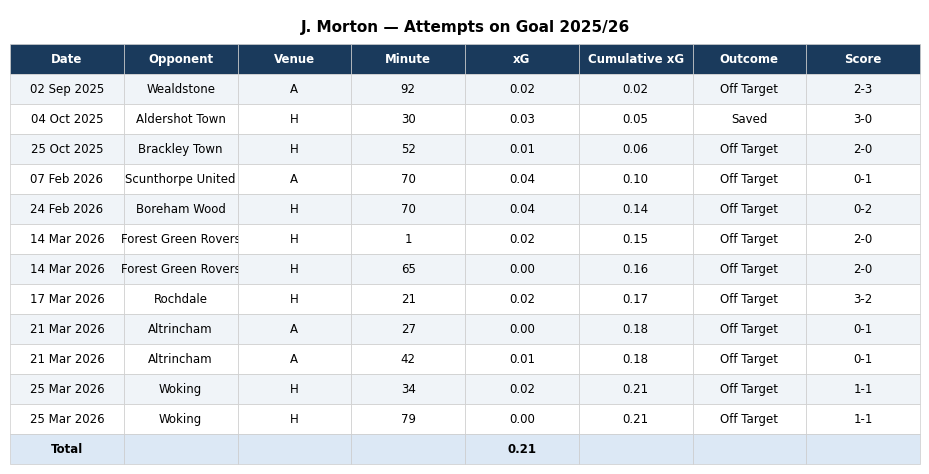

Saved to dallas_attempts.png


In [21]:
from wyscout.team import get_team_squad
from datetime import datetime

# Find A Dallas in the squad
squad_data = get_team_squad(SOUTHEND, SEASON)
dallas = next(
    (p for p in squad_data["squad"] if "Morton" in p.get("lastName", "") or "Morton" in p.get("shortName", "")),
    None,
)
if dallas is None:
    print("A Dallas not found in squad")
else:
    A_DALLAS = dallas["wyId"]

    rows = []
    all_season_matches = get_team_matches(SOUTHEND, SEASON)

    for m in all_season_matches["matches"]:
        if m["status"] != "Played":
            continue
        try:
            match, match_details, squad, team_details = get_match_details_and_events(
                SOUTHEND, m["matchId"], False
            )
        except ValueError:
            continue

        f, a = 0, 0
        venue = ""
        opp_id = None
        for t in match_details["teamsData"].values():
            if t["teamId"] == SOUTHEND:
                venue = "H" if t["side"] == "home" else "A"
                f = t["score"]
            else:
                opp_id = t["teamId"]
                a = t["score"]

        score = f"{f}-{a}"
        opposition = team_details[opp_id]["name"]
        match_date = datetime.strptime(match["matchDate"].split(" ")[0], "%Y-%m-%d")
        date_str = match_date.strftime("%d %b %Y")

        dallas_shots = [
            e for e in match["events"]
            if e["type"]["primary"] in ("shot", "penalty") and e["player"]["id"] == A_DALLAS
        ]

        for s in dallas_shots:
            if s["shot"]["isGoal"]:
                outcome = "Goal"
            elif s["shot"]["onTarget"]:
                outcome = "Saved"
            else:
                outcome = "Off Target"

            rows.append({
                "_date_sort": match_date,
                "Date": date_str,
                "Opponent": opposition,
                "Venue": venue,
                "Minute": s["minute"],
                "xG": s["shot"]["xg"],
                "Outcome": outcome,
                "Score": score,
            })

    df_dallas = pd.DataFrame(rows)
    if df_dallas.empty:
        print(f"No shots found for {dallas.get('shortName', 'A Dallas')}")
    else:
        df_dallas = df_dallas.sort_values("_date_sort").drop(columns=["_date_sort"]).reset_index(drop=True)
        df_dallas["Cumulative xG"] = df_dallas["xG"].cumsum()

        totals = pd.DataFrame([{
            "Date": "Total",
            "Opponent": "",
            "Venue": "",
            "Minute": "",
            "xG": df_dallas["xG"].sum(),
            "Cumulative xG": "",
            "Outcome": "",
            "Score": "",
        }])
        df_display = pd.concat([df_dallas, totals], ignore_index=True)

        display(
            df_display.style
            .format({"xG": "{:.2f}", "Cumulative xG": lambda v: f"{v:.2f}" if isinstance(v, float) else ""})
            .set_caption(f"{dallas.get('shortName', 'A Dallas')} — Attempts on Goal 2025/26")
            .hide(axis="index")
        )

        # ── image output ──────────────────────────────────────────────────────
        player_name = dallas.get("shortName", "A Dallas")

        col_order = ["Date", "Opponent", "Venue", "Minute", "xG", "Cumulative xG", "Outcome", "Score"]
        fmt = {"xG": "{:.2f}", "Cumulative xG": lambda v: f"{v:.2f}" if isinstance(v, float) else ""}

        def fmt_cell(col, val):
            if col in fmt:
                f = fmt[col]
                return f(val) if callable(f) else f.format(val)
            return "" if pd.isna(val) or val == "" else str(val)

        cell_text = [[fmt_cell(c, row[c]) for c in col_order] for _, row in df_display.iterrows()]

        n_rows = len(df_display)
        col_widths = [1.4, 2.2, 0.7, 0.8, 0.7, 1.4, 1.1, 0.8]
        row_h   = 0.30   # inches per row (including header)
        title_h = 0.35   # inches for title
        fig_w   = sum(col_widths)
        fig_h   = row_h * (n_rows + 1) + title_h  # +1 for header row

        fig, ax = plt.subplots(figsize=(fig_w, fig_h))
        ax.axis("off")
        fig.patch.set_facecolor("white")
        plt.subplots_adjust(top=1.0, bottom=0.0, left=0.0, right=1.0)

        title_frac = title_h / fig_h
        ax.text(
            0.5, 1.0 - title_frac / 2,
            f"{player_name} — Attempts on Goal 2025/26",
            transform=ax.transAxes, fontsize=11, fontweight="bold",
            ha="center", va="center",
        )

        tbl = ax.table(
            cellText=cell_text,
            colLabels=col_order,
            cellLoc="center",
            bbox=[0, 0, 1, 1 - title_frac],
        )
        tbl.auto_set_font_size(False)
        tbl.set_fontsize(8.5)

        HEADER_BG = "#1a3a5c"
        HEADER_FG = "white"
        ROW_ODD   = "#f0f4f8"
        ROW_EVEN  = "white"
        TOTAL_BG  = "#dce8f5"
        GOAL_FG   = "#1a7a1a"

        for (r, c), cell in tbl.get_celld().items():
            cell.set_edgecolor("#cccccc")
            cell.set_linewidth(0.5)
            if r == 0:
                cell.set_facecolor(HEADER_BG)
                cell.set_text_props(color=HEADER_FG, fontweight="bold")
            elif r == n_rows:
                cell.set_facecolor(TOTAL_BG)
                cell.set_text_props(fontweight="bold")
            else:
                cell.set_facecolor(ROW_ODD if r % 2 == 1 else ROW_EVEN)
                if col_order[c] == "Outcome" and cell.get_text().get_text() == "Goal":
                    cell.set_text_props(color=GOAL_FG, fontweight="bold")

        plt.savefig("dallas_attempts.png", dpi=150, bbox_inches="tight", facecolor="white")
        plt.show()
        print("Saved to dallas_attempts.png")


## Attempts with and without Harry Cardwell (superseded)

An earlier version of the cell below, kept by accident - it lacks the highlighting of his own attempts. Safe to delete.

,minutes,shots,on target,xG,goals,shots/90,on target/90,xG/90,goals/90,xG/shot
,,,,,,,,,,
Harry Cardwell on,581,89,38,13.34,11,13.79,5.89,2.07,1.70,0.150
Harry Cardwell off,139,31,12,3.93,6,20.07,7.77,2.54,3.88,0.127


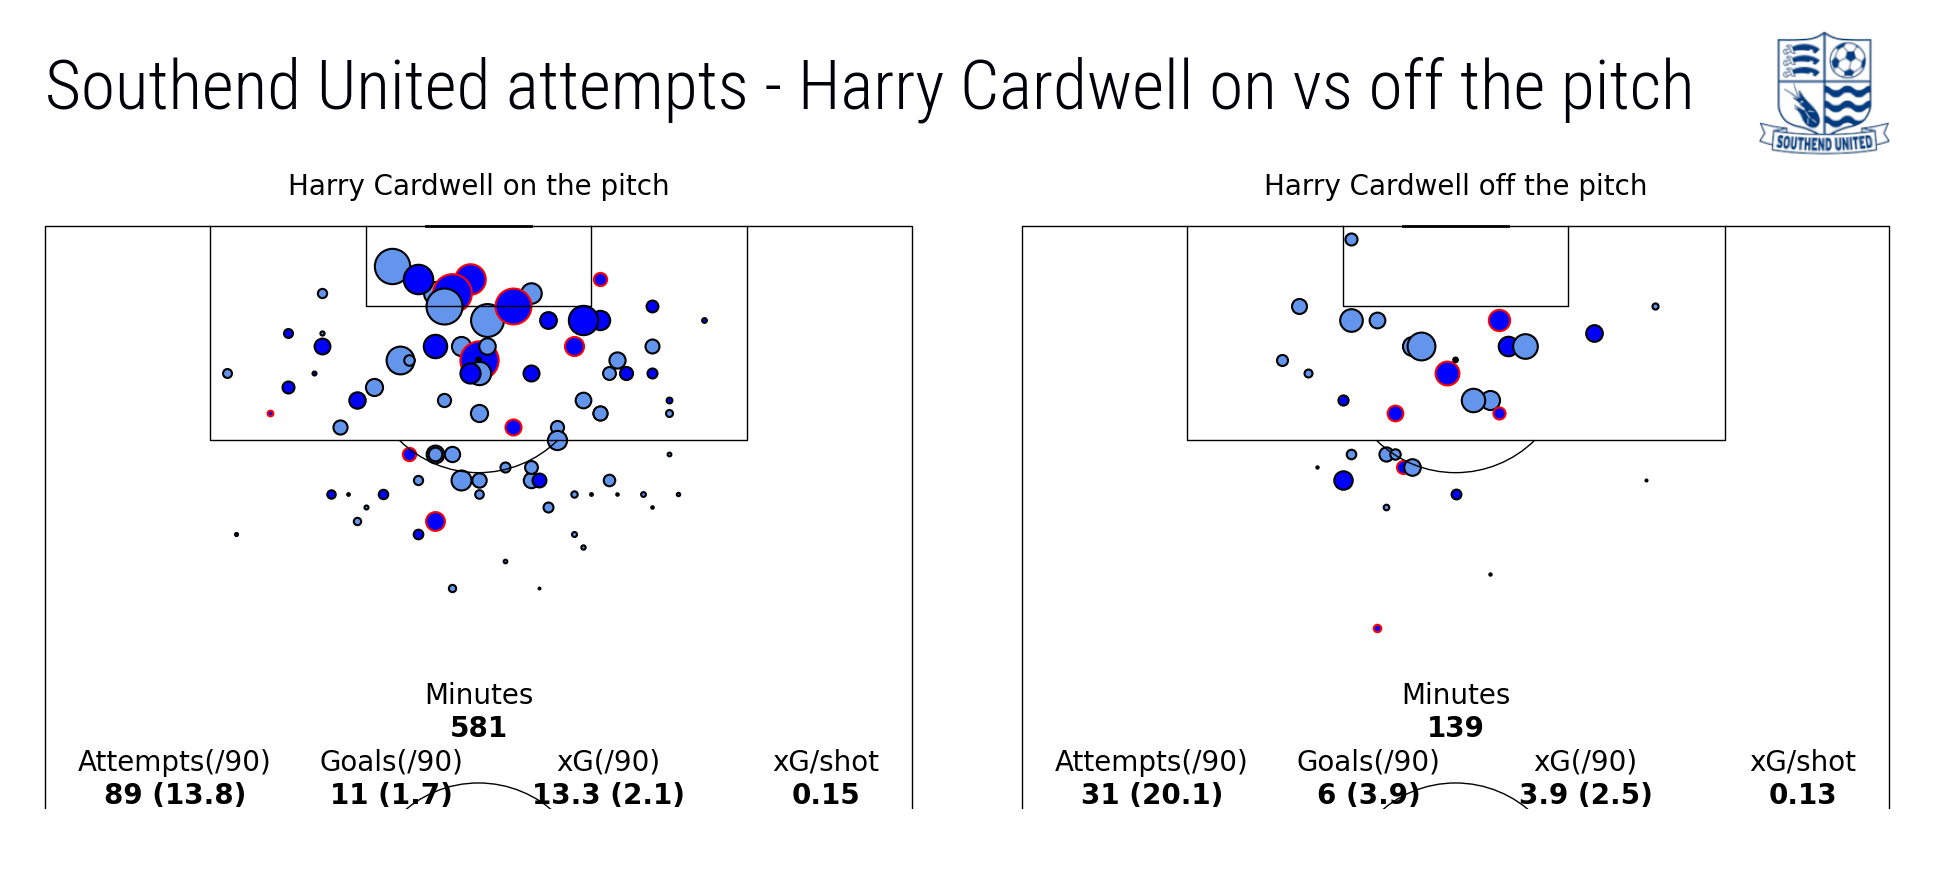

In [ ]:
# Southend attempts with Harry Cardwell on the pitch vs off it, this season
from wyscout.match import get_match_details, get_match_details_and_events
from wyscout.stats import get_player_spells, get_minutes_played, event_in_spells
from wyscout.viz.match import plot_attempts

PLAYER = H_CARDWELL
PLAYER_NAME = "Harry Cardwell"

played = [
    m for m in get_team_matches(SOUTHEND, SEASON)["matches"] if m["status"] == "Played"
]

# minutes he was on the pitch in each match (nominal, so a full game is 90)
spells = {
    m["matchId"]: get_player_spells(PLAYER, SOUTHEND, get_match_details(m["matchId"]))
    for m in played
}
minutes_on = sum(get_minutes_played(s) for s in spells.values())
minutes_off = len(played) * 90 - minutes_on


def on_pitch(match, event):
    return event_in_spells(event, spells[match["matchId"]])


def off_pitch(match, event):
    return not on_pitch(match, event)


def is_attempt(event):
    """Shots, penalties and direct free kicks - as plotted below."""
    primary = event["type"]["primary"]
    secondary = event["type"]["secondary"] or []
    return bool(event.get("shot")) and (
        primary in ("shot", "penalty") or (primary == "free_kick" and "shot" in secondary)
    )


on_shots, off_shots = [], []
for m in played:
    try:
        match, *_ = get_match_details_and_events(SOUTHEND, m["matchId"], True)
    except ValueError:
        continue
    for e in match["events"]:
        if e["team"]["id"] != SOUTHEND or not is_attempt(e):
            continue
        (on_shots if on_pitch(m, e) else off_shots).append(e)


def summarise(label, shots, minutes):
    per_90 = minutes / 90 if minutes else 0
    goals = sum(s["shot"]["isGoal"] for s in shots)
    on_target = sum(bool(s["shot"]["onTarget"]) for s in shots)
    xg = sum(s["shot"]["xg"] for s in shots)
    return {
        "": label,
        "minutes": round(minutes),
        "shots": len(shots),
        "on target": on_target,
        "xG": round(xg, 2),
        "goals": goals,
        "shots/90": round(len(shots) / per_90, 2) if per_90 else 0,
        "on target/90": round(on_target / per_90, 2) if per_90 else 0,
        "xG/90": round(xg / per_90, 2) if per_90 else 0,
        "goals/90": round(goals / per_90, 2) if per_90 else 0,
        "xG/shot": round(xg / len(shots), 3) if shots else 0,
    }


df_cardwell = pd.DataFrame(
    [
        summarise(f"{PLAYER_NAME} on", on_shots, minutes_on),
        summarise(f"{PLAYER_NAME} off", off_shots, minutes_off),
    ]
).set_index("")
display(df_cardwell)

plot_attempts(
    [played, played],
    SOUTHEND,
    fig_height=10,
    shot_colors=("blue", "cornflowerblue"),
    header_text=f"Southend United attempts - {PLAYER_NAME} on vs off the pitch",
    subtitle_text=[f"{PLAYER_NAME} on the pitch", f"{PLAYER_NAME} off the pitch"],
    include_pens=True,
    include_free_kicks=True,
    event_filter=[on_pitch, off_pitch],
    group_minutes=[minutes_on, minutes_off],
)

## Attempts with and without Harry Cardwell

Works out the minutes Cardwell was on the pitch in each match from the lineups and substitutions, then splits every Southend attempt by whether he was on at the time. Minutes are nominal, so a full match is 90 and a half-time substitution is 45.

Prints a summary table - minutes, attempts, on target, xG and goals, as totals and per 90 - then:

**Visualisation:** two half-pitches, on the pitch versus off it. Attempts are sized by xG and ringed red for goals as before, and Cardwell's own attempts are picked out in yellow - gold on target, khaki off. The tiles read per 90 rather than per game, since the two panels cover very different amounts of football.

In [ ]:
# Southend attempts with Harry Cardwell on the pitch vs off it, this season
from wyscout.match import get_match_details, get_match_details_and_events
from wyscout.stats import get_player_spells, get_minutes_played, event_in_spells
from wyscout.viz.match import plot_attempts

PLAYER = H_CARDWELL
PLAYER_NAME = "Harry Cardwell"

played = [
    m for m in get_team_matches(SOUTHEND, SEASON)["matches"] if m["status"] == "Played"
]

# minutes he was on the pitch in each match (nominal, so a full game is 90)
spells = {
    m["matchId"]: get_player_spells(PLAYER, SOUTHEND, get_match_details(m["matchId"]))
    for m in played
}
minutes_on = sum(get_minutes_played(s) for s in spells.values())
minutes_off = len(played) * 90 - minutes_on


def on_pitch(match, event):
    return event_in_spells(event, spells[match["matchId"]])


def off_pitch(match, event):
    return not on_pitch(match, event)


def cardwell_shot(match, event):
    return event["player"]["id"] == PLAYER


def is_attempt(event):
    """Shots, penalties and direct free kicks - as plotted below."""
    primary = event["type"]["primary"]
    secondary = event["type"]["secondary"] or []
    return bool(event.get("shot")) and (
        primary in ("shot", "penalty") or (primary == "free_kick" and "shot" in secondary)
    )


on_shots, off_shots = [], []
for m in played:
    try:
        match, *_ = get_match_details_and_events(SOUTHEND, m["matchId"], True)
    except ValueError:
        continue
    for e in match["events"]:
        if e["team"]["id"] != SOUTHEND or not is_attempt(e):
            continue
        (on_shots if on_pitch(m, e) else off_shots).append(e)


def summarise(label, shots, minutes):
    per_90 = minutes / 90 if minutes else 0
    goals = sum(s["shot"]["isGoal"] for s in shots)
    on_target = sum(bool(s["shot"]["onTarget"]) for s in shots)
    xg = sum(s["shot"]["xg"] for s in shots)
    return {
        "": label,
        "minutes": round(minutes),
        "shots": len(shots),
        "on target": on_target,
        "xG": round(xg, 2),
        "goals": goals,
        "shots/90": round(len(shots) / per_90, 2) if per_90 else 0,
        "on target/90": round(on_target / per_90, 2) if per_90 else 0,
        "xG/90": round(xg / per_90, 2) if per_90 else 0,
        "goals/90": round(goals / per_90, 2) if per_90 else 0,
        "xG/shot": round(xg / len(shots), 3) if shots else 0,
    }


df_cardwell = pd.DataFrame(
    [
        summarise(f"{PLAYER_NAME} on", on_shots, minutes_on),
        summarise(f"{PLAYER_NAME} off", off_shots, minutes_off),
    ]
).set_index("")
display(df_cardwell)

plot_attempts(
    [played, played],
    SOUTHEND,
    fig_height=10,
    shot_colors=("blue", "cornflowerblue"),
    header_text=f"Southend United attempts - {PLAYER_NAME} on vs off the pitch",
    subtitle_text=[
        f"{PLAYER_NAME} on the pitch (his own attempts in yellow)",
        f"{PLAYER_NAME} off the pitch",
    ],
    include_pens=True,
    include_free_kicks=True,
    event_filter=[on_pitch, off_pitch],
    group_minutes=[minutes_on, minutes_off],
    highlight_filter=[cardwell_shot, None],
    highlight_colors=("gold", "khaki"),
)

## Every goal, split by whether Cardwell was on

Lists each Southend goal with the date, opposition and venue, scorer, minute, xG and how it came about.

Output: two tables, one for goals scored with him on the pitch and one for those scored after he came off. Depends on `played`, `on_pitch` and `is_attempt` from the cell above.

In [ ]:
# Every Southend goal this season, split by whether Cardwell was on the pitch
goal_rows = {"on": [], "off": []}

for m in played:
    try:
        match, match_details, squad, team_details = get_match_details_and_events(
            SOUTHEND, m["matchId"], True
        )
    except ValueError:
        continue

    venue = "H" if match_details["teamsData"][str(SOUTHEND)]["side"] == "home" else "A"
    opposition = next(
        team_details[t["teamId"]]["name"]
        for t in match_details["teamsData"].values()
        if t["teamId"] != SOUTHEND
    )

    for e in match["events"]:
        if e["team"]["id"] != SOUTHEND or not is_attempt(e) or not e["shot"]["isGoal"]:
            continue
        goal_rows["on" if on_pitch(m, e) else "off"].append(
            {
                "date": m["date"][:10],
                "opposition": f"{opposition} ({venue})",
                "scorer": e["player"]["name"],
                "min": e["minute"],
                "xG": round(e["shot"]["xg"], 2),
                "type": e["type"]["primary"],
            }
        )

df_goals_on = pd.DataFrame(goal_rows["on"]).sort_values(["date", "min"])
df_goals_off = pd.DataFrame(goal_rows["off"]).sort_values(["date", "min"])

print(f"Goals with {PLAYER_NAME} on the pitch ({minutes_on} mins)")
display(df_goals_on)
print(f"Goals with {PLAYER_NAME} off the pitch ({minutes_off} mins)")
display(df_goals_off)

Goals with Harry Cardwell on the pitch (581 mins)


,date,opposition,scorer,min,xG,type
8,2026-08-08,Altrincham (A),L. Chambers-Parillon,36,0.02,shot
9,2026-08-08,Altrincham (A),O. Coker,51,0.13,shot
10,2026-08-08,Altrincham (A),H. Cardwell,84,0.19,shot
7,2026-08-15,Scunthorpe United (H),J. Popoola,22,0.78,shot
5,2026-08-22,Solihull Moors (A),O. Coker,27,0.67,shot
6,2026-08-22,Solihull Moors (A),J. Popoola,38,0.48,shot
4,2026-08-28,Kidderminster Harriers (H),L. Chambers-Parillon,9,0.44,shot
3,2026-08-31,Woking (A),H. Cardwell,37,0.76,penalty
0,2026-09-05,Yeovil Town (H),D. Oldaker,65,0.18,free_kick
1,2026-09-05,Yeovil Town (H),L. Chambers-Parillon,78,0.09,shot


Goals with Harry Cardwell off the pitch (139 mins)


,date,opposition,scorer,min,xG,type
5,2026-08-22,Solihull Moors (A),C. Kendall,91,0.03,shot
3,2026-09-12,Carlisle United (A),L. Chambers-Parillon,82,0.29,shot
4,2026-09-12,Carlisle United (A),K. McAdam,91,0.09,shot
0,2026-09-15,Tamworth (H),L. Chambers-Parillon,59,0.08,shot
1,2026-09-15,Tamworth (H),P. Omochere,67,0.23,shot
2,2026-09-15,Tamworth (H),S. Austin,81,0.13,shot


## Season on season - this season against last

Rebuilds both seasons' league results from the fixtures, oldest first, dropping play-off matches by keeping only the round nearly every match belongs to. Running totals for points, goals for and against, and goal difference are carried down the season.

**Visualisation:** one figure in two parts.

The table is one row per game number, which is how the two seasons line up: game 1 of each season is a different opponent. Each season gets its own fixture and result column, shaded green, amber and red. Alongside them sits the one fixture-for-fixture comparison worth having - how last season went against the team we played this time, same opponent and same venue - reading "not played" for a club that wasn't in the division. Then the running totals for each season side by side: points, goals for and against, and goal difference.

Three line charts follow, each comparing the two seasons over the same number of games, with the current figures in the chart title: cumulative points and cumulative goal difference, then scored and conceded together on one axis - same scale, so the gap between the lines is the goal difference and the two seasons can be read off against each other directly. This season is solid with markers, last season dashed.

`PREV_SEASON` sets the comparison season; the labels come from the API, so nothing needs editing when `SEASON` moves on.

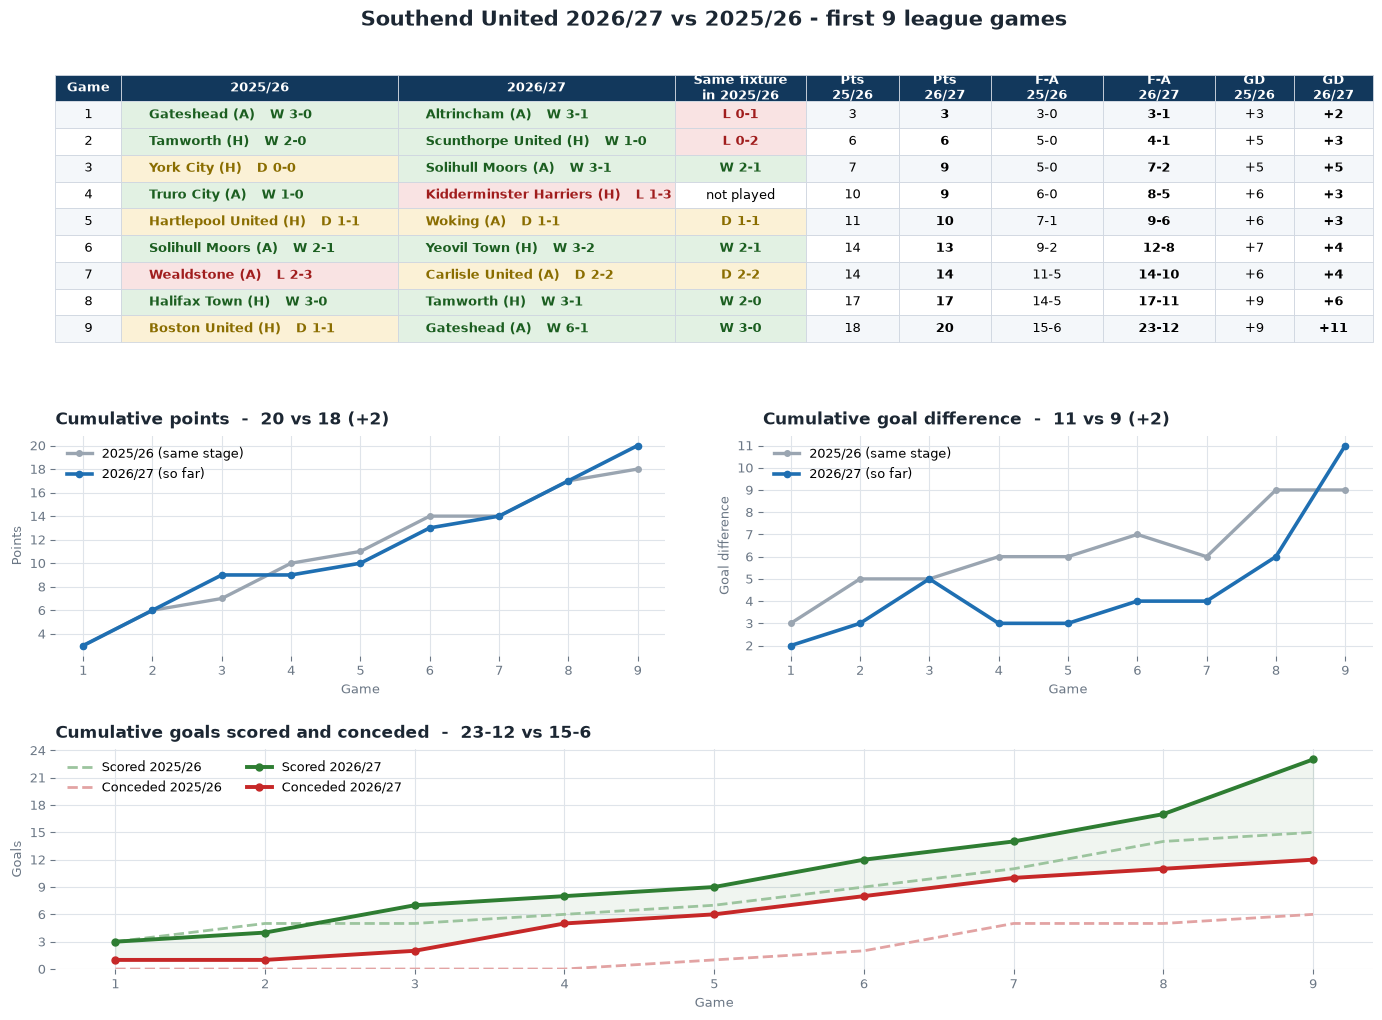

In [14]:
# Season-on-season comparison: this season against last
from collections import Counter

import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
from wyscout.competitions import get_season_details
from wyscout.match import get_team_matches, get_match_details
from wyscout.team import get_team_details

PREV_SEASON = SEASON_2025


def season_label(season_id):
    """e.g. "2026/2027" -> "2026/27" """
    name = get_season_details(season_id)["name"]
    start, _, end = name.partition("/")
    return f"{start}/{end[-2:]}" if end else name


THIS_LABEL = season_label(SEASON)
PREV_LABEL = season_label(PREV_SEASON)


def season_results(season_id):
    """League results for the season, oldest first, with running totals."""
    matches = [
        m
        for m in get_team_matches(SOUTHEND, season_id)["matches"]
        if m["status"] == "Played"
    ]
    # the league round is the one nearly every match belongs to - drops play-offs
    league_round = Counter(m["roundId"] for m in matches).most_common(1)[0][0]
    matches = sorted(
        (m for m in matches if m["roundId"] == league_round), key=lambda m: m["date"]
    )

    rows = []
    points = goals_for = goals_against = 0

    for game, m in enumerate(matches, start=1):
        details = get_match_details(m["matchId"])
        us = details["teamsData"][str(SOUTHEND)]
        them = next(
            t for t in details["teamsData"].values() if t["teamId"] != SOUTHEND
        )

        gf, ga = us["score"], them["score"]
        result = "W" if gf > ga else "D" if gf == ga else "L"
        points += {"W": 3, "D": 1, "L": 0}[result]
        goals_for += gf
        goals_against += ga

        rows.append(
            {
                "game": game,
                "date": m["date"][:10],
                "opponent": get_team_details(them["teamId"])["name"],
                "venue": "H" if us["side"] == "home" else "A",
                "gf": gf,
                "ga": ga,
                "gd": gf - ga,
                "result": result,
                "points": points,
                "cum_gf": goals_for,
                "cum_ga": goals_against,
                "cum_gd": goals_for - goals_against,
            }
        )

    return pd.DataFrame(rows)


this_season = season_results(SEASON)
prev_season = season_results(PREV_SEASON)
games = len(this_season)

# last season's result in the same fixture - same opponent, same venue
prev_by_fixture = {(r.opponent, r.venue): r for r in prev_season.itertuples()}

NAVY = "#12385c"
THIS_COL = "#1f6fb2"
PREV_COL = "#9aa5b1"
GF_COL = "#2e7d32"
GA_COL = "#c62828"
GF_PREV = "#9cc49e"
GA_PREV = "#e2a3a3"
TEXT = "#1c2733"
MUTED = "#6b7785"
GRID = "#dfe4ea"
RESULT_FG = {"W": "#1b5e20", "D": "#8a6d00", "L": "#a01d1d"}
RESULT_BG = {"W": "#e2f1e3", "D": "#fbf1d6", "L": "#f9e3e3"}

fig = plt.figure(figsize=(17, 12), facecolor="white")
grid = gridspec.GridSpec(
    3, 2, figure=fig, height_ratios=[1.35, 1, 1], hspace=0.38, wspace=0.16
)

# ── table ────────────────────────────────────────────────────────────────────
ax_table = fig.add_subplot(grid[0, :])
ax_table.axis("off")

col_labels = [
    "Game",
    f"{PREV_LABEL}",
    f"{THIS_LABEL}",
    f"Same fixture\nin {PREV_LABEL}",
    f"Pts\n{PREV_LABEL[-5:]}",
    f"Pts\n{THIS_LABEL[-5:]}",
    f"F-A\n{PREV_LABEL[-5:]}",
    f"F-A\n{THIS_LABEL[-5:]}",
    f"GD\n{PREV_LABEL[-5:]}",
    f"GD\n{THIS_LABEL[-5:]}",
]

cell_text, result_cells = [], {}
for r in this_season.itertuples():
    # the same game number last season - a different fixture
    prev_game = prev_season[prev_season["game"] == r.game]
    p = prev_game.iloc[0] if len(prev_game) else None
    # and how last season went against the team we played this time
    prev_fixture = prev_by_fixture.get((r.opponent, r.venue))

    row_idx = len(cell_text) + 1
    result_cells[(row_idx, 2)] = r.result
    if p is not None:
        result_cells[(row_idx, 1)] = p["result"]
    if prev_fixture is not None:
        result_cells[(row_idx, 3)] = prev_fixture.result

    cell_text.append(
        [
            str(r.game),
            f"{p['opponent']} ({p['venue']})   {p['result']} {p['gf']}-{p['ga']}"
            if p is not None
            else "-",
            f"{r.opponent} ({r.venue})   {r.result} {r.gf}-{r.ga}",
            f"{prev_fixture.result} {prev_fixture.gf}-{prev_fixture.ga}"
            if prev_fixture is not None
            else "not played",
            str(p["points"]) if p is not None else "-",
            str(r.points),
            f"{p['cum_gf']}-{p['cum_ga']}" if p is not None else "-",
            f"{r.cum_gf}-{r.cum_ga}",
            f"{p['cum_gd']:+d}" if p is not None else "-",
            f"{r.cum_gd:+d}",
        ]
    )

table = ax_table.table(
    cellText=cell_text,
    colLabels=col_labels,
    cellLoc="center",
    colWidths=[0.05, 0.21, 0.21, 0.1, 0.07, 0.07, 0.085, 0.085, 0.06, 0.06],
    bbox=[0, 0, 1, 0.9],
)
table.auto_set_font_size(False)
table.set_fontsize(9)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor("#cfd6e0")
    cell.set_linewidth(0.6)
    cell.set_height(0.11)
    if row == 0:
        cell.set_facecolor(NAVY)
        cell.set_text_props(color="white", fontweight="bold")
    else:
        cell.set_facecolor("#f4f7fa" if row % 2 else "white")
        if col in (1, 2):
            cell.set_text_props(ha="left")
            cell._text.set_x(0.025)
        if (row, col) in result_cells:
            res = result_cells[(row, col)]
            cell.set_facecolor(RESULT_BG[res])
            cell.set_text_props(color=RESULT_FG[res], fontweight="bold")
        if col in (5, 7, 9):
            cell.set_text_props(fontweight="bold")

ax_table.set_title(
    f"Southend United {THIS_LABEL} vs {PREV_LABEL} - first {games} league games",
    fontsize=15,
    fontweight="bold",
    color=TEXT,
    pad=14,
)

# ── charts ───────────────────────────────────────────────────────────────────
def style(ax, title, ylabel):
    ax.set_title(title, fontsize=12, fontweight="bold", color=TEXT, pad=8, loc="left")
    ax.set_ylabel(ylabel, fontsize=9.5, color=MUTED)
    ax.set_xlabel("Game", fontsize=9.5, color=MUTED)
    ax.grid(True, color=GRID, linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, labelsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_xlim(0.6, games + 0.4)
    ax.set_xticks(range(1, games + 1))
    ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True))


def compare(ax, column, title, ylabel, this_color=THIS_COL):
    """Both seasons over the games played so far - last season in grey."""
    same_stage = prev_season.head(games)
    ax.plot(
        same_stage["game"], same_stage[column],
        color=PREV_COL, linewidth=2.4, marker="o", markersize=4,
        zorder=2, label=f"{PREV_LABEL} (same stage)",
    )
    ax.plot(
        this_season["game"], this_season[column],
        color=this_color, linewidth=2.6, marker="o", markersize=4.5,
        zorder=3, label=f"{THIS_LABEL} (so far)",
    )

    now = this_season[column].iloc[-1]
    then = prev_season.loc[prev_season["game"] == games, column].iloc[0]
    diff = now - then

    style(ax, f"{title}  -  {now} vs {then} ({diff:+d})", ylabel)
    ax.legend(fontsize=9, frameon=False, loc="upper left")


compare(fig.add_subplot(grid[1, 0]), "points", "Cumulative points", "Points")
compare(fig.add_subplot(grid[1, 1]), "cum_gd", "Cumulative goal difference", "Goal difference")

# scored and conceded share one axis, so the gap between them is read directly
ax_goals = fig.add_subplot(grid[2, :])
same_stage = prev_season.head(games)

ax_goals.plot(same_stage["game"], same_stage["cum_gf"], color=GF_PREV, linewidth=2,
              linestyle="--", zorder=2, label=f"Scored {PREV_LABEL}")
ax_goals.plot(same_stage["game"], same_stage["cum_ga"], color=GA_PREV, linewidth=2,
              linestyle="--", zorder=2, label=f"Conceded {PREV_LABEL}")
ax_goals.fill_between(this_season["game"], this_season["cum_gf"], this_season["cum_ga"],
                      color=GF_COL, alpha=0.07, zorder=1)
ax_goals.plot(this_season["game"], this_season["cum_gf"], color=GF_COL, linewidth=2.8,
              marker="o", markersize=5, zorder=3, label=f"Scored {THIS_LABEL}")
ax_goals.plot(this_season["game"], this_season["cum_ga"], color=GA_COL, linewidth=2.8,
              marker="o", markersize=5, zorder=3, label=f"Conceded {THIS_LABEL}")

gf_now, ga_now = this_season["cum_gf"].iloc[-1], this_season["cum_ga"].iloc[-1]
gf_then = same_stage["cum_gf"].iloc[-1]
ga_then = same_stage["cum_ga"].iloc[-1]
style(
    ax_goals,
    f"Cumulative goals scored and conceded  -  {gf_now}-{ga_now} vs {gf_then}-{ga_then}",
    "Goals",
)
ax_goals.set_ylim(bottom=0)
ax_goals.legend(fontsize=9, frameon=False, loc="upper left", ncol=2)

plt.show()

## League position and the gap to the top

The heavy lifting is in `wyscout.league_table.table_progression`, which rebuilds the whole division's table after every one of our match days and returns a row per match: our position, points and goal difference, who led at the time, and how far off them we were. The table behind each row is every league match played up to and including that calendar day, so a position counts the day's other results too - and, as in a real table, teams may have played different numbers of games.

That is a lot of matches, so the first run fills the match cache and is slow; after that it is a fraction of a second per season.

**Visualisation:** three charts. The top one is league position after each match day, this season against last at the same stage, with the promotion place and the play-off places shaded, and the position written above each point. Note it is drawn to the range we've occupied rather than all 24 places.

Below that, the two gaps to the top, both plotted as us minus the leaders - above the line is better than them, below is worse. Gold marks the match days we were top, where the gap runs back to second instead. The chart titles name the current leaders.

This cell needs the one above it for its colours, labels and `PREV_SEASON`.

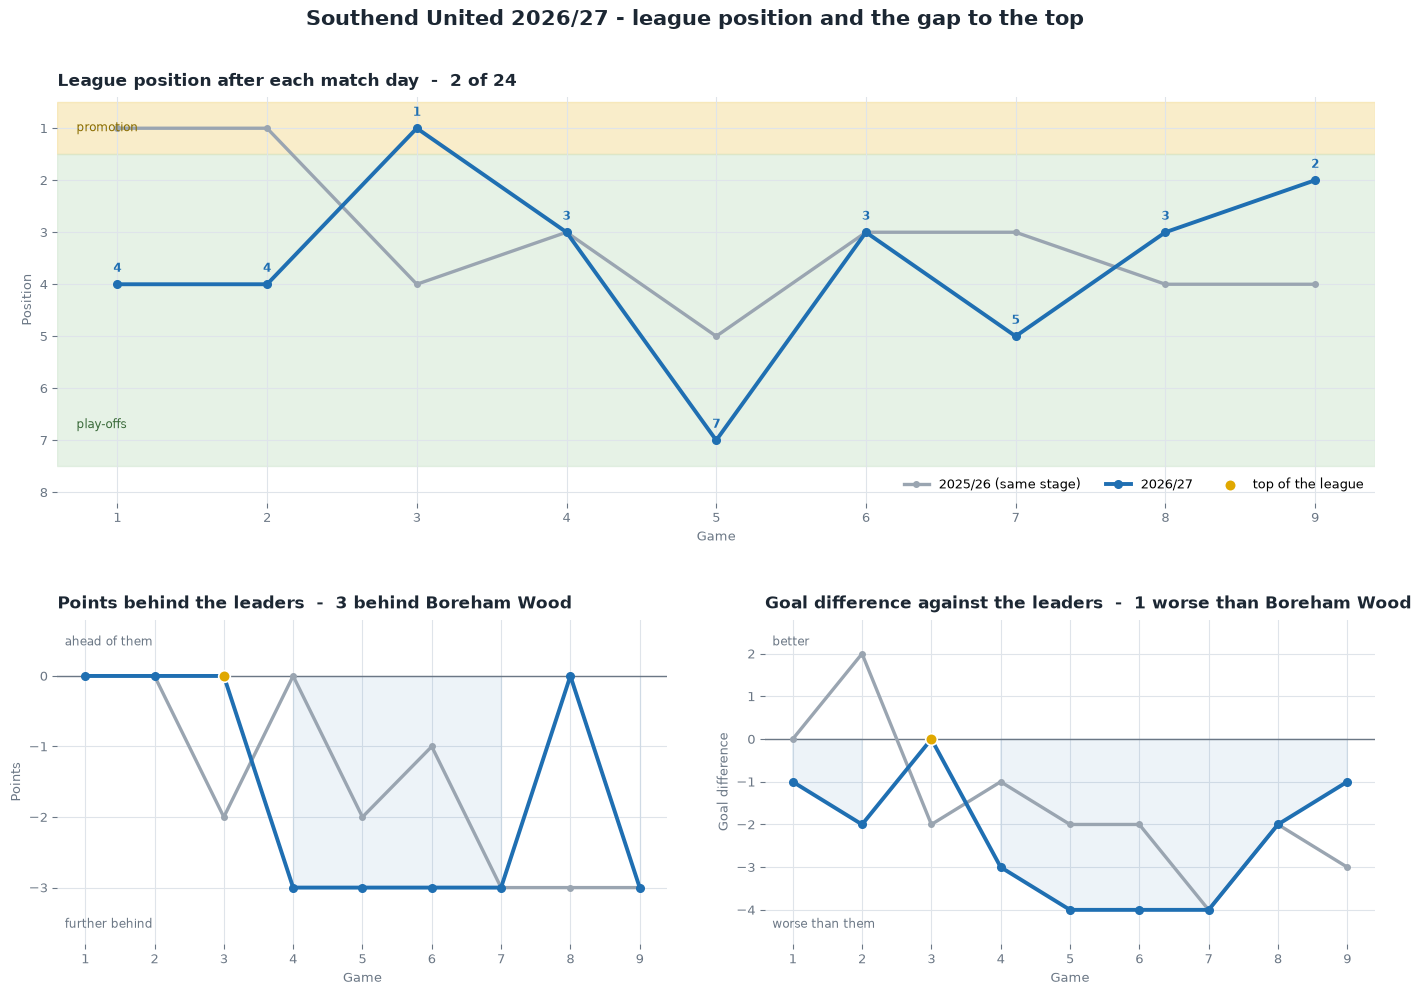

In [15]:
# League position and the gap to the top - depends on the cell above
from wyscout.league_table import table_progression

PROMOTION_PLACES = 1        # National League: champions go up
PLAYOFF_PLACES = 7          # 2nd to 7th play off

this_prog = pd.DataFrame(table_progression(SEASON, NATIONAL_LEAGUE, SOUTHEND))
prev_prog = pd.DataFrame(table_progression(PREV_SEASON, NATIONAL_LEAGUE, SOUTHEND))
prev_stage = prev_prog.head(len(this_prog))
teams_in_league = 24

fig = plt.figure(figsize=(17, 11), facecolor="white")
grid = gridspec.GridSpec(2, 2, figure=fig, height_ratios=[1.25, 1], hspace=0.32, wspace=0.16)

latest = this_prog.iloc[-1]
fig.suptitle(
    f"Southend United {THIS_LABEL} - league position and the gap to the top",
    fontsize=15, fontweight="bold", color=TEXT, y=0.96,
)

# ── league position after each match day ─────────────────────────────────────
ax_pos = fig.add_subplot(grid[0, :])
ax_pos.axhspan(0.5, PROMOTION_PLACES + 0.5, color="#f3d98b", alpha=0.45, zorder=0)
ax_pos.axhspan(PROMOTION_PLACES + 0.5, PLAYOFF_PLACES + 0.5, color="#cfe6cf", alpha=0.5, zorder=0)
ax_pos.text(0.7, PROMOTION_PLACES, " promotion", fontsize=8.5, color="#8a6d00", va="center")
ax_pos.text(0.7, PLAYOFF_PLACES - 0.3, " play-offs", fontsize=8.5, color="#3b6b3b", va="center")

ax_pos.plot(prev_stage["game"], prev_stage["position"], color=PREV_COL, linewidth=2.4,
            marker="o", markersize=4, zorder=2, label=f"{PREV_LABEL} (same stage)")
ax_pos.plot(this_prog["game"], this_prog["position"], color=THIS_COL, linewidth=2.8,
            marker="o", markersize=5.5, zorder=3, label=f"{THIS_LABEL}")

for r in this_prog.itertuples():
    ax_pos.annotate(f"{r.position}", xy=(r.game, r.position), xytext=(0, 9),
                    textcoords="offset points", ha="center", fontsize=8.5,
                    fontweight="bold", color=THIS_COL, zorder=4)

style(ax_pos, f"League position after each match day  -  {int(latest['position'])} of {teams_in_league}", "Position")
worst = int(max(this_prog["position"].max(), prev_stage["position"].max()))
ax_pos.set_ylim(worst + 1.2, 0.4)
ax_pos.set_yticks(range(1, worst + 2))
ax_pos.scatter([], [], s=70, color="#e0a800", edgecolor="white", linewidth=1.2,
               label="top of the league")
ax_pos.legend(fontsize=9, frameon=False, loc="lower right", ncol=3)

# ── the gap to the leaders ───────────────────────────────────────────────────
def gap_chart(ax, column, title, ylabel, behind_label, ahead_label):
    """Plotted as us minus the leaders, so below the line is behind them."""
    this_gap = -this_prog[column]
    prev_gap = -prev_stage[column]

    ax.axhline(0, color=MUTED, linewidth=1, zorder=2)
    ax.plot(prev_stage["game"], prev_gap, color=PREV_COL, linewidth=2.4,
            marker="o", markersize=4, zorder=3)
    ax.fill_between(this_prog["game"], this_gap, 0, where=this_gap < 0,
                    color=THIS_COL, alpha=0.08, zorder=1)
    ax.plot(this_prog["game"], this_gap, color=THIS_COL, linewidth=2.8,
            marker="o", markersize=5.5, zorder=4)

    # top of the league - the gap then runs the other way, back to second
    top = this_prog["is_leader"]
    if top.any():
        ax.scatter(this_prog["game"][top], this_gap[top], s=70, color="#e0a800",
                   edgecolor="white", linewidth=1.2, zorder=5)

    style(ax, title, ylabel)
    ax.yaxis.set_major_locator(ticker.MaxNLocator(integer=True))
    low = min(this_gap.min(), prev_gap.min())
    high = max(this_gap.max(), prev_gap.max())
    ax.set_ylim(low - 0.8, high + 0.8)
    ax.annotate(ahead_label, xy=(0.012, 0.92), xycoords="axes fraction",
                fontsize=8.5, color=MUTED)
    ax.annotate(behind_label, xy=(0.012, 0.05), xycoords="axes fraction",
                fontsize=8.5, color=MUTED)


points_gap = int(latest["points_behind"])
gd_gap = int(latest["goal_difference_behind"])
leader = latest["leader"]

gap_chart(
    fig.add_subplot(grid[1, 0]), "points_behind",
    "Points behind the leaders  -  "
    + (f"{points_gap} behind {leader}" if points_gap > 0
       else f"level with {leader}" if points_gap == 0
       else f"{-points_gap} clear of {leader}"),
    "Points", "further behind", "ahead of them",
)
gap_chart(
    fig.add_subplot(grid[1, 1]), "goal_difference_behind",
    "Goal difference against the leaders  -  "
    + (f"{gd_gap} worse than {leader}" if gd_gap > 0
       else f"level with {leader}" if gd_gap == 0
       else f"{-gd_gap} better than {leader}"),
    "Goal difference", "worse than them", "better",
)

plt.show()